In [1]:
import sys, json, joblib
sys.path.append("../src")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown
from sklearn.metrics import classification_report
from config import PROCESSED_DIR, MODELS_DIR, FIGURES_DIR, ROOT

sns.set_theme(style="whitegrid")
val = pd.read_csv(ROOT / "reports" / "validation_results.csv")
test = pd.read_csv(ROOT / "reports" / "test_results.csv")
pred = pd.read_csv(ROOT / "reports" / "test_predictions.csv", parse_dates=["date"])
model = joblib.load(MODELS_DIR / "best_model.joblib")
best = (MODELS_DIR / "best_model_name.txt").read_text().strip()
FEATURES = json.loads((PROCESSED_DIR / "feature_columns.json").read_text())

print("Modèle retenu :", best)
print("\nValidation"); display(val.round(4))
print("Test"); display(test.round(4))

Modèle retenu : logreg

Validation


,model,accuracy,log_loss,f1_macro,f1_draw
0,logreg,0.5150,1.0040,0.3762,0.0000
1,random_forest,0.5118,1.0060,0.3727,0.0030
2,gradient_boosting,0.5086,1.0063,0.3723,0.0118
3,tree,0.5118,1.0099,0.3823,0.0488
4,baseline,0.4458,1.0680,0.2056,0.0000


Test


,model,accuracy,log_loss,f1_macro,f1_draw
0,baseline,0.4284,1.0760,0.1999,0.0000
1,logreg,0.4989,1.0148,0.3713,0.0000
2,tree,0.4883,1.0272,0.3665,0.0058
3,random_forest,0.4992,1.0199,0.3713,0.0030
4,gradient_boosting,0.4981,1.0208,0.3721,0.0088


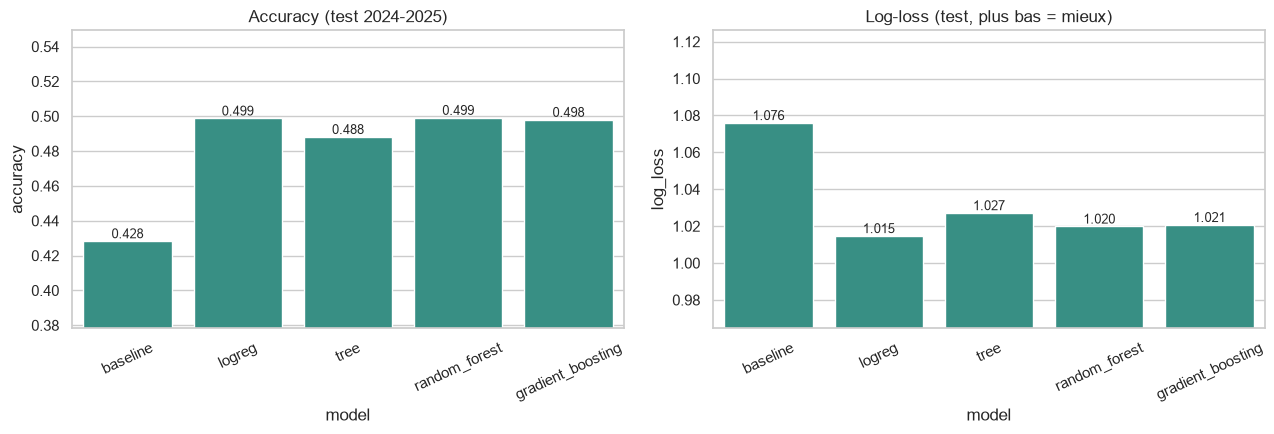

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, title in zip(axes, ["accuracy", "log_loss"],
                          ["Accuracy (test 2024-2025)", "Log-loss (test, plus bas = mieux)"]):
    sns.barplot(data=test, x="model", y=col, ax=ax, color="#2a9d8f")
    ax.set_title(title)
    ax.set_ylim(test[col].min() - 0.05, test[col].max() + 0.05)
    ax.tick_params(axis="x", rotation=25)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison.png", dpi=150)
plt.show()

              precision    recall  f1-score   support

           H       0.51      0.78      0.61      1131
           D       0.00      0.00      0.00       670
           A       0.49      0.51      0.50       839

    accuracy                           0.50      2640
   macro avg       0.33      0.43      0.37      2640
weighted avg       0.37      0.50      0.42      2640



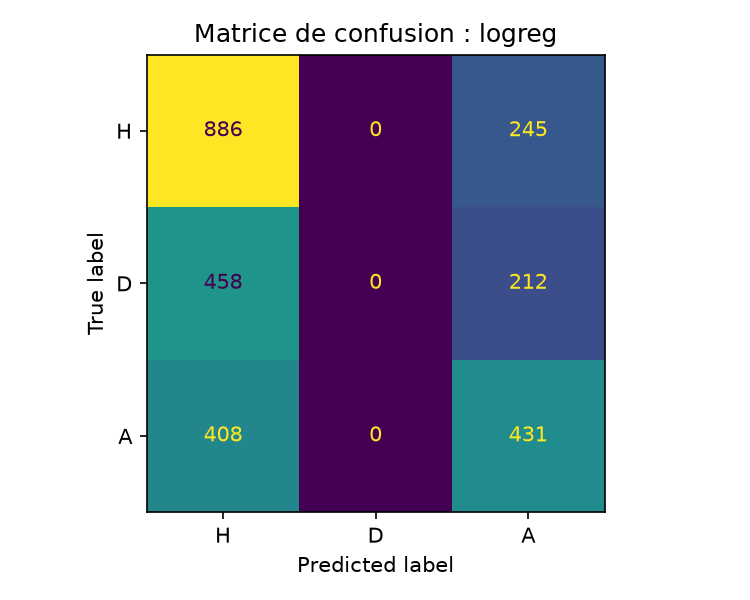

In [3]:
print(classification_report(pred["result"], pred["pred"], labels=["H", "D", "A"], zero_division=0))
Image(str(FIGURES_DIR / f"confusion_{best}.png"))

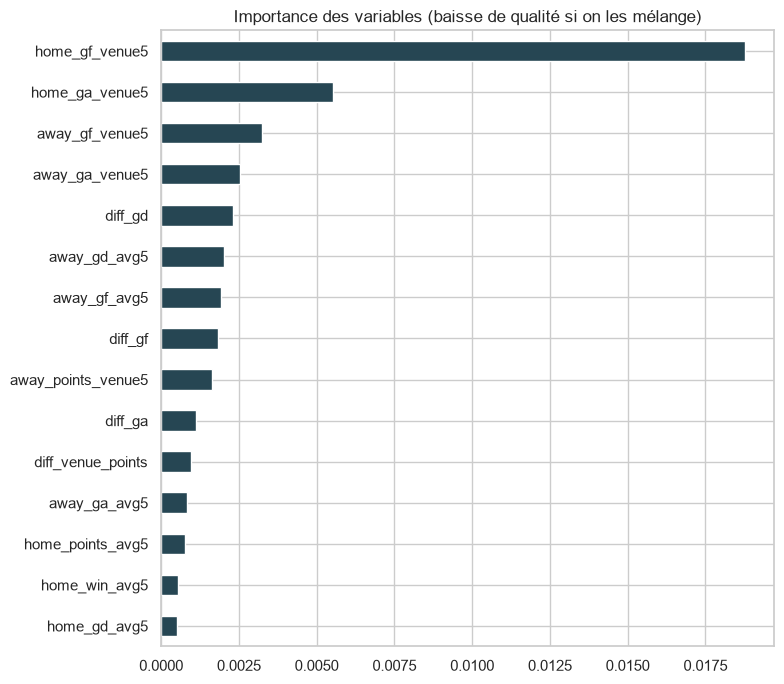

In [4]:
from sklearn.inspection import permutation_importance

feat = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"], dtype={"season": str})
te = feat[feat.season == "2425"]
r = permutation_importance(model, te[FEATURES], te["result"],
                           scoring="neg_log_loss", n_repeats=5, random_state=42)
imp = pd.Series(r.importances_mean, index=FEATURES).sort_values()

plt.figure(figsize=(8, 7))
imp.tail(15).plot(kind="barh", color="#264653")
plt.title("Importance des variables (baisse de qualité si on les mélange)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_importance.png", dpi=150)
plt.show()

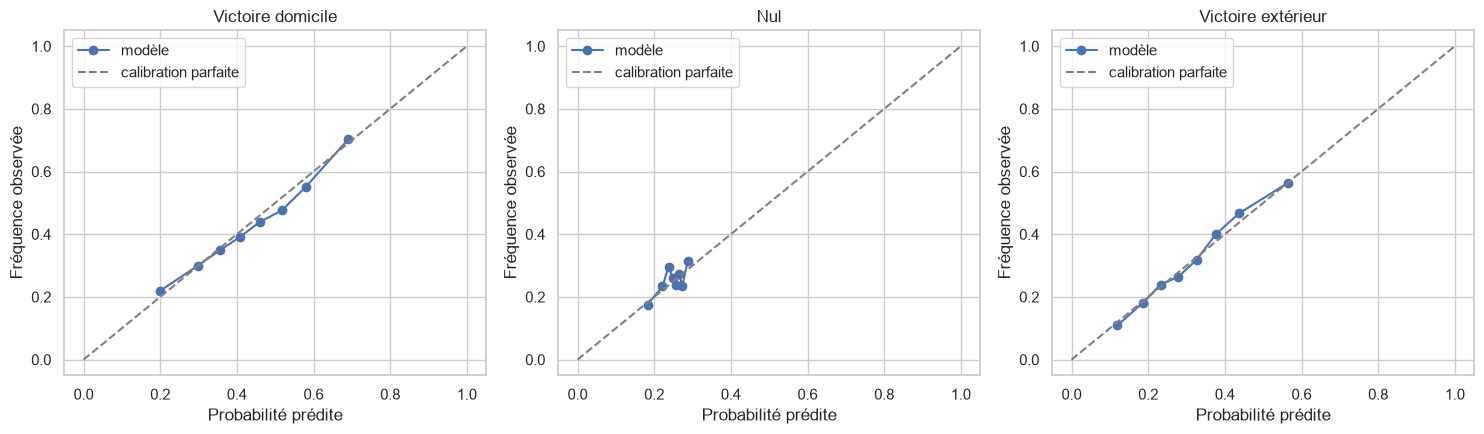

In [5]:
from sklearn.calibration import calibration_curve

names = {"H": "Victoire domicile", "D": "Nul", "A": "Victoire extérieur"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c in zip(axes, ["H", "D", "A"]):
    y_bin = (pred["result"] == c).astype(int)
    frac, mean_p = calibration_curve(y_bin, pred[f"p_{c}"], n_bins=8, strategy="quantile")
    ax.plot(mean_p, frac, marker="o", label="modèle")
    ax.plot([0, 1], [0, 1], "--", color="grey", label="calibration parfaite")
    ax.set_title(names[c]); ax.set_xlabel("Probabilité prédite"); ax.set_ylabel("Fréquence observée")
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "calibration.png", dpi=150)
plt.show()

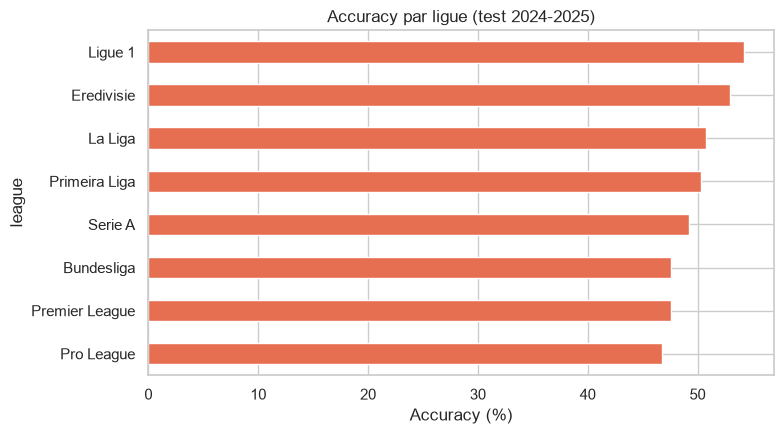

Part de chaque résultat réel prédit comme H / D / A (%) :


pred,A,H
result,,
A,51.4,48.6
D,31.6,68.4
H,21.7,78.3


In [6]:
pred["correct"] = pred["result"] == pred["pred"]
by_league = pred.groupby("league")["correct"].mean().sort_values() * 100

plt.figure(figsize=(8, 4.5))
by_league.plot(kind="barh", color="#e76f51")
plt.xlabel("Accuracy (%)"); plt.title("Accuracy par ligue (test 2024-2025)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_by_league.png", dpi=150)
plt.show()

print("Part de chaque résultat réel prédit comme H / D / A (%) :")
display((pd.crosstab(pred["result"], pred["pred"], normalize="index") * 100).round(1))

In [7]:
b = test[test.model == "baseline"].iloc[0]
m = test[test.model == best].iloc[0]
draw_recall = (pred[pred.result == "D"]["pred"] == "D").mean() * 100
home_pct = (pred["result"] == "H").mean() * 100

texte = f"""## Synthèse des résultats (test : saison 2024-2025, {len(pred)} matchs)

- **Modèle retenu** (log-loss de validation la plus basse) : **{best}**.
- **Accuracy** : {m.accuracy*100:.1f} % contre {b.accuracy*100:.1f} % pour la référence ({m.accuracy*100 - b.accuracy*100:+.1f} points).
- **Log-loss** : {m.log_loss:.3f} contre {b.log_loss:.3f} pour la référence ({m.log_loss - b.log_loss:+.3f}).
- **Matchs nuls** : seulement {draw_recall:.1f} % des nuls réels sont repérés (F1 = {m.f1_draw:.2f}). La classe « nul » reste très difficile à prédire.
- **Ligues** : la meilleure accuracy est en **{by_league.index[-1]}** ({by_league.iloc[-1]:.1f} %), la plus faible en **{by_league.index[0]}** ({by_league.iloc[0]:.1f} %). Avec environ {pred.groupby('league').size().min()} à {pred.groupby('league').size().max()} matchs par ligue, ces écarts restent fragiles.

### Limites
- Les variables reposent uniquement sur les buts et les résultats passés (pas de blessures, compositions, effectifs, ni matchs de coupe).
- Les équipes récemment promues ont peu d'historique.
- Une seule saison de test : les performances peuvent varier d'une saison à l'autre.
- Le football comporte une part importante de hasard : un gain modeste par rapport à la référence est un résultat réaliste.
"""
display(Markdown(texte))
(ROOT / "reports" / "results_summary.md").write_text(texte, encoding="utf-8")

## Synthèse des résultats (test : saison 2024-2025, 2640 matchs)

- **Modèle retenu** (log-loss de validation la plus basse) : **logreg**.
- **Accuracy** : 49.9 % contre 42.8 % pour la référence (+7.0 points).
- **Log-loss** : 1.015 contre 1.076 pour la référence (-0.061).
- **Matchs nuls** : seulement 0.0 % des nuls réels sont repérés (F1 = 0.00). La classe « nul » reste très difficile à prédire.
- **Ligues** : la meilleure accuracy est en **Ligue 1** (54.2 %), la plus faible en **Pro League** (46.7 %). Avec environ 294 à 380 matchs par ligue, ces écarts restent fragiles.

### Limites
- Les variables reposent uniquement sur les buts et les résultats passés (pas de blessures, compositions, effectifs, ni matchs de coupe).
- Les équipes récemment promues ont peu d'historique.
- Une seule saison de test : les performances peuvent varier d'une saison à l'autre.
- Le football comporte une part importante de hasard : un gain modeste par rapport à la référence est un résultat réaliste.


994